<a href="https://colab.research.google.com/github/LunaGar1/Practica4-Vision-e-IA/blob/main/Reto4_P4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reto 4: Restauración de imágenes SAR despeckeadas con SwinIR (sin reentrenar)

Se eligen automáticamente las de más bordes y estructuras, que es donde se nota la pérdida de detalle. Opcionalmente se añaden imágenes propias (ópticas o SAR).

## 0. Instalación y configuración

In [ ]:
!pip -q install timm python-docx
!git clone -q https://github.com/JingyunLiang/SwinIR.git /content/SwinIR 2>/dev/null || echo "SwinIR ya clonado"
# Compatibilidad con versiones nuevas de timm
!sed -i 's/timm.models.layers/timm.layers/' /content/SwinIR/models/network_swinir.py

SwinIR ya clonado


In [ ]:
import os, sys, glob, random, time, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

import tensorflow as tf
for g in tf.config.list_physical_devices('GPU'):      # TF y PyTorch comparten GPU: evita que TF la acapare
    tf.config.experimental.set_memory_growth(g, True)
from tensorflow import keras

import torch
sys.path.append('/content/SwinIR')
from models.network_swinir import SwinIR

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo PyTorch:', device)
SEED = 42; random.seed(SEED); np.random.seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

Dispositivo PyTorch: cuda
Mounted at /content/drive


In [ ]:
ZIP_PATH = '/content/drive/MyDrive/VisionComputadorIA/SAR despeckling filters dataset.zip'
DEST     = '/content/SAR despeckling filters dataset'
AE_PATH  = '/content/drive/MyDrive/SAR_reto_resultados/AE_tuned.keras'   # AE del reto anterior (o AE_paper.keras)
OUT_DIR  = '/content/drive/MyDrive/SAR_reto_resultados/swinir'
EXTRA_DIR = None        # opcional: carpeta con imágenes propias (ópticas/SAR) para inspección visual
N_SELECT  = 4           # imágenes que se analizan visualmente (mínimo 3)
N_METRIC  = 10          # imágenes (incluye las N_SELECT) para las métricas promedio
FORCE_SIGMA = None      # None = se elige el mejor σ de SwinIR automáticamente (15, 25 o 50)
LEE_ENL = 16            # ENL nominal para el filtro de Lee (el ruidoso del dataset ronda 16-26)
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(DEST):
    os.makedirs(DEST)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(DEST)
BASE = f'{DEST}/SAR despeckling filters dataset/Main folder'
NOISY_VAL_DIR, GT_VAL_DIR = f'{BASE}/Noisy_val', f'{BASE}/GTruth_val'
print(len(os.listdir(NOISY_VAL_DIR)), len(os.listdir(GT_VAL_DIR)))

100 100


## 1. Datos: selección de imágenes con bordes y estructuras

(100, 512, 512) (100, 512, 512)
Imágenes seleccionadas (más bordes): [np.int64(43), np.int64(44), np.int64(92), np.int64(41)]


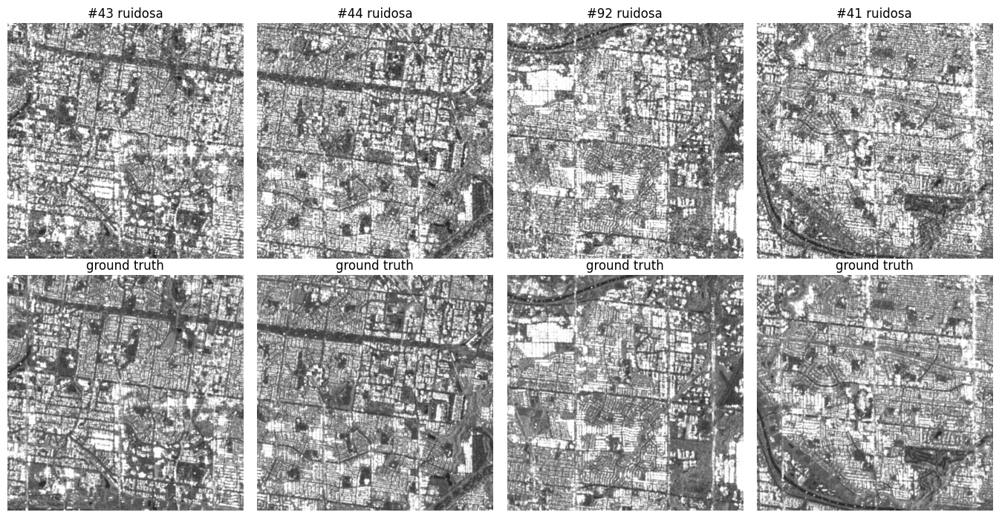

In [ ]:
def list_imgs(d):
    return sorted(glob.glob(os.path.join(d, '*.tif*')) + glob.glob(os.path.join(d, '*.TIF*')))
def load_gray(p):
    return np.asarray(Image.open(p).convert('L'), dtype=np.float32) / 255.   # (512,512) en [0,1]

nf, gf = list_imgs(NOISY_VAL_DIR), list_imgs(GT_VAL_DIR)
assert len(nf) == len(gf) > 0
N = np.stack([load_gray(p) for p in nf]); G = np.stack([load_gray(p) for p in gf])
print(N.shape, G.shape)

def grad_mag(a): return np.hypot(ndimage.sobel(a, 0), ndimage.sobel(a, 1))
# Criterio: más energía de bordes en el GT (descarta imágenes casi negras, p. ej. agua)
edge_score = np.array([grad_mag(g).mean() if g.mean() > 0.12 else -1 for g in G])
sel = list(np.argsort(edge_score)[::-1][:N_SELECT])
rest = [i for i in np.random.RandomState(SEED).permutation(len(N)) if i not in sel]
eval_ids = sel + rest[:max(0, N_METRIC - len(sel))]
print('Imágenes seleccionadas (más bordes):', sel)

fig, axs = plt.subplots(2, len(sel), figsize=(3.4*len(sel), 7))
for k, i in enumerate(sel):
    axs[0, k].imshow(N[i], cmap='gray', vmin=0, vmax=1); axs[0, k].set_title(f'#{i} ruidosa'); axs[0, k].axis('off')
    axs[1, k].imshow(G[i], cmap='gray', vmin=0, vmax=1); axs[1, k].set_title('ground truth'); axs[1, k].axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/00_seleccion.png', dpi=140); plt.show()

## 2. Despeckling (paso previo): AE entrenado en el reto 1 y filtro de Lee

In [ ]:
ae = keras.models.load_model(AE_PATH, compile=False)     # compile=False: la pérdida personalizada no hace falta para inferir
def ae_filter(x): return np.clip(ae.predict(x[None, ..., None], verbose=0)[0, ..., 0], 0, 1)

def lee_filter(img, size=7, L=LEE_ENL):
    m  = ndimage.uniform_filter(img, size)
    m2 = ndimage.uniform_filter(img**2, size)
    var = np.maximum(m2 - m**2, 0)
    cu2 = 1.0 / L                                        # coef. de variación del speckle
    ci2 = var / (m**2 + 1e-8)
    w = np.clip(1 - cu2 / (ci2 + 1e-8), 0, 1)
    return np.clip(m + w * (img - m), 0, 1)

## 3. SwinIR preentrenado (restauración)

Se usa el modelo oficial *grayscale image denoising* (SwinIR-M, entrenado en DFWB con ruido gaussiano σ ∈ {15, 25, 50}).
**Aviso de dominio:** SwinIR nunca vio imágenes SAR ni speckle; aquí se usa como restaurador genérico sobre imágenes *ya despeckeadas*, igual que en el artículo.

In [ ]:
W_DIR = '/content/swinir_weights'; os.makedirs(W_DIR, exist_ok=True)
URL = 'https://github.com/JingyunLiang/SwinIR/releases/download/v0.0/004_grayDN_DFWB_s128w8_SwinIR-M_noise{s}.pth'
_models = {}

def get_swinir(sigma):
    if sigma in _models: return _models[sigma]
    path = f'{W_DIR}/004_grayDN_DFWB_s128w8_SwinIR-M_noise{sigma}.pth'
    if not os.path.exists(path):
        import urllib.request; urllib.request.urlretrieve(URL.format(s=sigma), path)
    m = SwinIR(upscale=1, in_chans=1, img_size=128, window_size=8, img_range=1.,
               depths=[6]*6, embed_dim=180, num_heads=[6]*6, mlp_ratio=2,
               upsampler='', resi_connection='1conv')
    ck = torch.load(path, map_location='cpu')
    m.load_state_dict(ck['params'] if 'params' in ck else ck, strict=True)
    _models[sigma] = m.eval().to(device)
    return _models[sigma]

@torch.no_grad()
def _run(model, img):
    t = torch.from_numpy(img.astype(np.float32))[None, None].to(device)
    return model(t).clamp(0, 1)[0, 0].cpu().numpy()

@torch.no_grad()
def swinir(img, sigma, tile=256, ov=32):
    """Restaura una imagen (H,W) en [0,1]. Usa la imagen completa; si no cabe en GPU, por mosaicos."""
    model = get_swinir(sigma)
    try:
        return _run(model, img)
    except RuntimeError as e:
        if 'out of memory' not in str(e).lower(): raise
        torch.cuda.empty_cache()
        H, W = img.shape; out = np.zeros_like(img); cnt = np.zeros_like(img); step = tile - ov
        ys = list(range(0, max(H-tile, 0)+1, step)); xs = list(range(0, max(W-tile, 0)+1, step))
        if ys[-1] + tile < H: ys.append(H - tile)
        if xs[-1] + tile < W: xs.append(W - tile)
        for y in ys:
            for x in xs:
                out[y:y+tile, x:x+tile] += _run(model, img[y:y+tile, x:x+tile]); cnt[y:y+tile, x:x+tile] += 1
        return out / cnt

t0 = time.time(); _ = swinir(N[sel[0]], 15); print(f'SwinIR cargado y probado: {time.time()-t0:.1f}s')

/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


SwinIR cargado y probado: 11.2s


## 4. Métricas

PSNR/SSIM contra el GT (misma implementación que el reto anterior). ENL en la ROI de 32×32 más homogénea del GT (se compara con el ENL del GT: **más alto no siempre es mejor**, puede ser sobre-suavizado). **EPI** = correlación entre el gradiente de la salida y el del GT (1 = bordes idénticos; baja si se borran bordes).

In [ ]:
def best_roi(gt, bs=32, min_mean=0.05):
    H, W = gt.shape
    b = gt[:H//bs*bs, :W//bs*bs].reshape(H//bs, bs, W//bs, bs).transpose(0,2,1,3).reshape(-1, bs, bs)
    m, s = b.mean((1,2)), b.std((1,2))
    cv = np.where(m > min_mean, s/(m+1e-8), np.inf)
    gy, gx = divmod(int(np.argmin(cv)), W//bs)
    return slice(gy*bs, (gy+1)*bs), slice(gx*bs, (gx+1)*bs)

def enl(a): return float(a.mean()**2 / (a.var() + 1e-12))
def epi(a, gt): return float(np.corrcoef(grad_mag(a).ravel(), grad_mag(gt).ravel())[0, 1])

def metrics(out, gt):
    t = lambda a: tf.convert_to_tensor(a[None, ..., None], tf.float32)
    ry, rx = best_roi(gt)
    return dict(PSNR=float(tf.image.psnr(t(out), t(gt), max_val=1.)[0]),
                SSIM=float(tf.image.ssim(t(out), t(gt), max_val=1.)[0]),
                ENL=enl(out[ry, rx]), EPI=epi(out, gt))

In [ ]:
def pipeline(i, sigma):
    noisy, gt = N[i], G[i]
    a, l = ae_filter(noisy), lee_filter(noisy)
    return {'Noisy': noisy, 'GT': gt,
            'AE': a,  'AE_R': swinir(a, sigma),
            'Lee': l, 'Lee_R': swinir(l, sigma),
            'Noisy_R': swinir(noisy, sigma)}          # control: restaurar directamente sin despeckling

# --- Barrido de σ (nivel del modelo SwinIR) sobre las imágenes seleccionadas ---
rows = []
for s in (15, 25, 50):
    for i in sel:
        v = pipeline(i, s)
        for k in ('AE_R', 'Lee_R'):
            rows.append(dict(sigma=s, img=i, variante=k, **metrics(v[k], v['GT'])))
sweep = pd.DataFrame(rows)
sw = sweep.groupby(['variante', 'sigma'])[['PSNR', 'SSIM', 'ENL', 'EPI']].mean().round(4)
sw.to_csv(f'{OUT_DIR}/barrido_sigma.csv'); display(sw)

SIGMA = FORCE_SIGMA or int(sweep[sweep.variante == 'AE_R'].groupby('sigma').SSIM.mean().idxmax())
print('σ usado en SwinIR:', SIGMA)

PSNR    SSIM          ENL     EPI
variante sigma                                      
AE_R     15     17.4767  0.4417    1491.9642  0.4124
         25     17.2057  0.3886  196646.5312  0.3606
         50     16.4178  0.2541  185178.7955  0.1987
Lee_R    15     19.2458  0.5063     218.3231  0.5029
         25     18.9807  0.4718     255.2361  0.4683
         50     18.3196  0.3894     472.3135  0.3829

σ usado en SwinIR: 15


## 5. Evaluación (antes vs. después de la restauración)

In [ ]:
results, keep = [], {}
for i in eval_ids:
    v = pipeline(i, SIGMA)
    if i in sel: keep[i] = v
    for k, img in v.items():
        if k == 'GT': continue
        results.append(dict(img=i, variante=k, **metrics(img, v['GT'])))
R = pd.DataFrame(results); R.to_csv(f'{OUT_DIR}/metricas_por_imagen.csv', index=False)

order = ['Noisy', 'AE', 'AE_R', 'Lee', 'Lee_R', 'Noisy_R']
gt_enl = np.mean([enl(G[i][best_roi(G[i])]) for i in eval_ids])
tab = R.groupby('variante')[['PSNR', 'SSIM', 'ENL', 'EPI']].mean().loc[order].round(4)
tab.to_csv(f'{OUT_DIR}/metricas_promedio.csv'); display(tab)
print(f'ENL objetivo (GT, ROI homogénea, promedio): {gt_enl:.1f}  |  n imágenes = {len(eval_ids)}')

# Solo las imágenes seleccionadas (las que se inspeccionan visualmente)
tab_sel = R[R.img.isin(sel)].groupby('variante')[['PSNR', 'SSIM', 'ENL', 'EPI']].mean().loc[order].round(4)
tab_sel.to_csv(f'{OUT_DIR}/metricas_seleccionadas.csv'); print('\nSolo imágenes seleccionadas:'); display(tab_sel)

,PSNR,SSIM,ENL,EPI
variante,,,,
Noisy,20.9026,0.6279,28.9718,0.6243
AE,21.3988,0.5850,323.6087,0.4852
AE_R,21.2271,0.5417,1474.8662,0.4548
Lee,22.2636,0.5711,172.2017,0.5350
Lee_R,22.2950,0.5696,4108.7928,0.5276
Noisy_R,21.6274,0.6778,3189.4354,0.6536


ENL objetivo (GT, ROI homogénea, promedio): 134.7  |  n imágenes = 10

Solo imágenes seleccionadas:


,PSNR,SSIM,ENL,EPI
variante,,,,
Noisy,20.0436,0.7530,33.6681,0.7153
AE,17.7500,0.5006,447.4139,0.4650
AE_R,17.4767,0.4417,1491.9627,0.4124
Lee,19.3113,0.5125,179.9946,0.5133
Lee_R,19.2458,0.5063,218.3231,0.5029
Noisy_R,20.4527,0.7722,37.8639,0.7318


In [ ]:
# Efecto neto de la restauración: Δ = (con SwinIR) − (sin SwinIR), y % de imágenes en que mejora
piv = R.pivot(index='img', columns='variante')
out = []
for base in ('AE', 'Lee'):
    for m in ('PSNR', 'SSIM', 'EPI', 'ENL'):
        d = piv[m][base + '_R'] - piv[m][base]
        out.append(dict(filtro=base, metrica=m, delta_medio=d.mean(), pct_imagenes_que_mejoran=100*(d > 0).mean()))
delta = pd.DataFrame(out).round(4); delta.to_csv(f'{OUT_DIR}/efecto_restauracion.csv', index=False); display(delta)

,filtro,metrica,delta_medio,pct_imagenes_que_mejoran
0,AE,PSNR,-0.1718,20.0
1,AE,SSIM,-0.0434,0.0
2,AE,EPI,-0.0304,0.0
3,AE,ENL,1151.2575,100.0
4,Lee,PSNR,0.0314,40.0
5,Lee,SSIM,-0.0015,30.0
6,Lee,EPI,-0.0074,20.0
7,Lee,ENL,3936.5911,100.0


## 6. Validación visual

Qué observar: **bordes** (¿se recuperan o se emborronan más?), **artefactos** (texturas inventadas, patrones repetitivos, halos), **detalle** perdido/recuperado, y si la restauración **cambia el brillo/contraste** global.

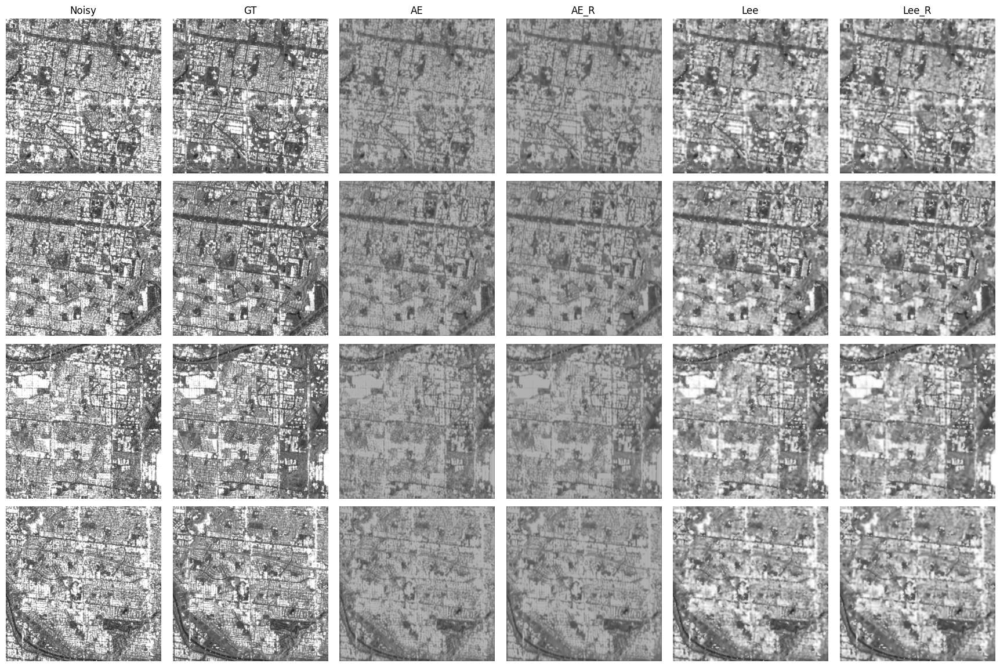

In [ ]:
def show_grid(keys=('Noisy', 'GT', 'AE', 'AE_R', 'Lee', 'Lee_R')):
    fig, axs = plt.subplots(len(sel), len(keys), figsize=(2.9*len(keys), 2.9*len(sel)))
    for r, i in enumerate(sel):
        for c, k in enumerate(keys):
            axs[r, c].imshow(keep[i][k], cmap='gray', vmin=0, vmax=1); axs[r, c].axis('off')
            if r == 0: axs[r, c].set_title(k)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/01_comparacion.png', dpi=140); plt.show()
show_grid()

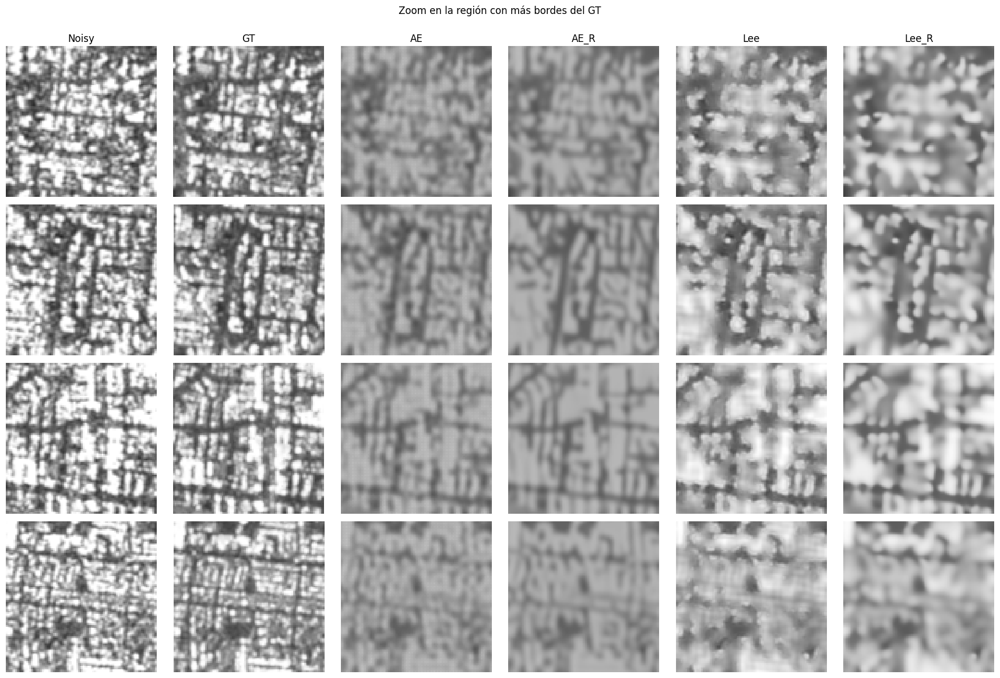

In [ ]:
def edge_crop(gt, s=96, stride=16):
    g = grad_mag(gt); best, pos = -1, (0, 0)
    for y in range(0, gt.shape[0]-s+1, stride):
        for x in range(0, gt.shape[1]-s+1, stride):
            v = g[y:y+s, x:x+s].mean()
            if v > best: best, pos = v, (y, x)
    return pos

def show_zoom(s=96):
    keys = ['Noisy', 'GT', 'AE', 'AE_R', 'Lee', 'Lee_R']
    fig, axs = plt.subplots(len(sel), len(keys), figsize=(2.9*len(keys), 2.9*len(sel)))
    for r, i in enumerate(sel):
        y, x = edge_crop(keep[i]['GT'], s)
        for c, k in enumerate(keys):
            axs[r, c].imshow(keep[i][k][y:y+s, x:x+s], cmap='gray', vmin=0, vmax=1, interpolation='nearest'); axs[r, c].axis('off')
            if r == 0: axs[r, c].set_title(k)
    plt.suptitle('Zoom en la región con más bordes del GT', y=1.0); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/02_zoom_bordes.png', dpi=140); plt.show()
show_zoom()

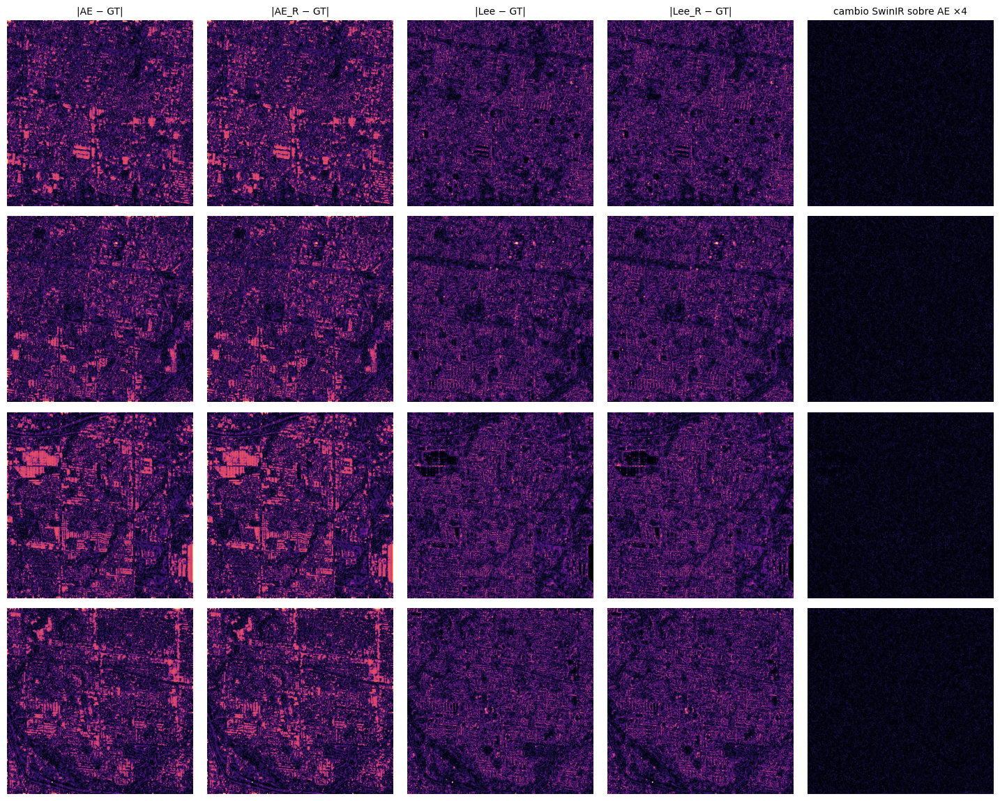

In [ ]:
# Mapas: error contra el GT antes/después, y QUÉ cambió SwinIR (|X_R − X|, ×4 para verlo)
def show_maps():
    titles = ['|AE − GT|', '|AE_R − GT|', '|Lee − GT|', '|Lee_R − GT|', 'cambio SwinIR sobre AE ×4']
    fig, axs = plt.subplots(len(sel), 5, figsize=(14.5, 2.9*len(sel)))
    for r, i in enumerate(sel):
        v = keep[i]
        maps = [abs(v['AE']-v['GT']), abs(v['AE_R']-v['GT']), abs(v['Lee']-v['GT']), abs(v['Lee_R']-v['GT']),
                np.clip(4*abs(v['AE_R']-v['AE']), 0, 1)]
        for c, m in enumerate(maps):
            axs[r, c].imshow(m, cmap='magma', vmin=0, vmax=0.5 if c < 4 else 1); axs[r, c].axis('off')
            if r == 0: axs[r, c].set_title(titles[c], fontsize=10)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/03_mapas_error_cambio.png', dpi=140); plt.show()
show_maps()

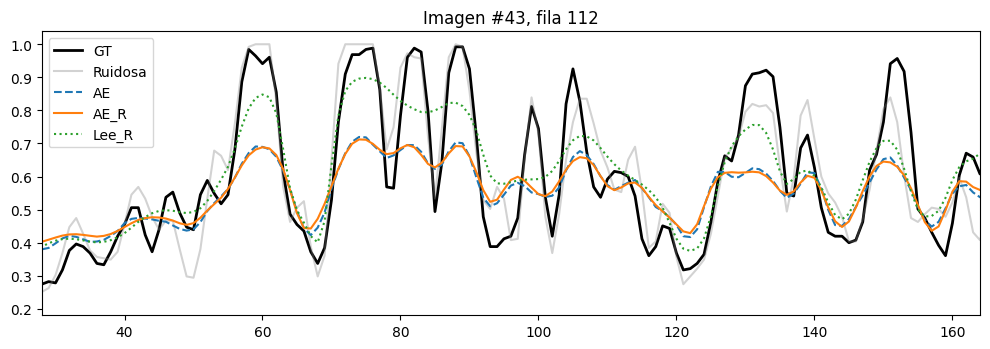

In [ ]:
# Perfil de intensidad sobre un borde: ¿se recupera la transición del GT?
i = sel[0]; y, x = edge_crop(keep[i]['GT']); row = y + 48
plt.figure(figsize=(10, 3.6))
plt.plot(keep[i]['GT'][row], 'k', lw=2, label='GT')
plt.plot(keep[i]['Noisy'][row], color='gray', alpha=.35, label='Ruidosa')
for k, st in [('AE', '--'), ('AE_R', '-'), ('Lee_R', ':')]:
    plt.plot(keep[i][k][row], st, label=k)
plt.xlim(x-20, x+116); plt.legend(); plt.title(f'Imagen #{i}, fila {row}'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/04_perfil_borde.png', dpi=140); plt.show()

In [ ]:
# Métricas por imagen seleccionada (para citar casos concretos en el informe)
display(R[R.img.isin(sel)].pivot(index='img', columns='variante', values='SSIM')[order].round(3).rename_axis('SSIM'))
display(R[R.img.isin(sel)].pivot(index='img', columns='variante', values='PSNR')[order].round(2).rename_axis('PSNR'))

variante,Noisy,AE,AE_R,Lee,Lee_R,Noisy_R
SSIM,,,,,,
41,0.736,0.485,0.422,0.477,0.476,0.757
43,0.770,0.516,0.460,0.549,0.538,0.788
44,0.767,0.506,0.449,0.515,0.507,0.785
92,0.739,0.495,0.435,0.509,0.505,0.758


variante,Noisy,AE,AE_R,Lee,Lee_R,Noisy_R
PSNR,,,,,,
41,19.93,17.88,17.60,19.39,19.36,20.38
43,20.12,17.74,17.47,19.34,19.23,20.51
44,20.14,18.18,17.89,19.24,19.16,20.52
92,19.98,17.19,16.95,19.28,19.23,20.40


## 8. Documento (Word) con las evidencias

Genera `informe_swinir.docx` en `OUT_DIR` con tablas y figuras. Las secciones de análisis y conclusiones quedan para que las completes con **lo que ves en TUS resultados** (guía abajo).

In [ ]:
from docx import Document
from docx.shared import Inches

doc = Document()
doc.add_heading('Restauración con SwinIR de imágenes SAR despeckeadas', 0)
doc.add_heading('1. Metodología', 1)
doc.add_paragraph(f'Pares SAR/GT del conjunto de validación del dataset (Sentinel-1, Toronto). {len(sel)} imágenes con más bordes '
                  f'para inspección visual y {len(eval_ids)} para métricas. Despeckling: autoencoder (reto 1) y filtro de Lee (ventana 7, ENL={LEE_ENL}). '
                  f'Restauración: SwinIR-M preentrenado de denoising en escala de grises, σ={SIGMA}, sin reentrenamiento.')
doc.add_heading('2. Resultados cuantitativos', 1)
def add_table(df, title):
    doc.add_paragraph(title)
    t = doc.add_table(rows=1, cols=len(df.columns)+1); t.style = 'Light Grid Accent 1'
    t.rows[0].cells[0].text = ''
    for j, c in enumerate(df.columns): t.rows[0].cells[j+1].text = str(c)
    for idx, row in df.iterrows():
        cells = t.add_row().cells; cells[0].text = str(idx)
        for j, v in enumerate(row): cells[j+1].text = f'{v:.3f}' if isinstance(v, (float, np.floating)) else str(v)
add_table(tab, f'Promedio ({len(eval_ids)} imágenes). ENL objetivo del GT ≈ {gt_enl:.1f}')
add_table(delta.set_index('filtro'), 'Efecto de la restauración (Δ = con SwinIR − sin SwinIR)')
doc.add_heading('3. Inspección visual', 1)
for f, cap in [('01_comparacion.png','Comparación general'), ('02_zoom_bordes.png','Zoom en bordes'),
               ('03_mapas_error_cambio.png','Mapas de error y de cambio'), ('04_perfil_borde.png','Perfil de intensidad')]:
    doc.add_paragraph(cap); doc.add_picture(f'{OUT_DIR}/{f}', width=Inches(6.3))
doc.add_heading('4. Análisis y conclusiones', 1)
doc.add_paragraph('[Completa aquí con tus observaciones; ver guía al final del notebook.]')
doc.save(f'{OUT_DIR}/informe_swinir.docx'); print('Guardado:', f'{OUT_DIR}/informe_swinir.docx')

## 9. Conclusiones

1. Resultados generales. Se aplicó SwinIR preentrenado (denoising en escala de grises, sin reentrenar) como etapa de restauración sobre imágenes despeckeadas con dos filtros: el autoencoder del reto anterior y un filtro de Lee propio. La evaluación usó 10 imágenes de validación (4 de ellas, las de más bordes, para inspección visual). En esta configuración, la restauración con SwinIR no mejoró de forma consistente la calidad de las imágenes despeckeadas.

(El ENL objetivo del ground truth es 134.7; EPI es la correlación de gradientes con el GT.)

2. Efecto neto de la restauración. Sobre el AE, SwinIR empeoró el PSNR (−0.17 dB), el SSIM (−0.043) y el EPI (−0.030), y en ninguna imagen mejoraron SSIM ni EPI. Sobre Lee el efecto fue prácticamente nulo: PSNR +0.03 dB (mejora en 40 % de las imágenes), SSIM −0.0015 y EPI −0.007. Es decir, SwinIR no recuperó bordes ni detalle perdido, y en el AE incluso los degradó levemente. Esto coincide con el artículo en el sentido de que PSNR y SSIM bajan algo tras la restauración, pero no se reproduce la mejora visual de detalle que el artículo reporta.

3. Nivel de ruido de SwinIR (σ). Entre σ = 15, 25 y 50, el mejor fue σ = 15, el menos agresivo, y todas las métricas empeoraron al subirlo. Por ejemplo, el SSIM de AE + SwinIR bajó de 0.442 a 0.389 y a 0.254 con σ = 25 y 50. Como las imágenes ya están despeckeadas, un σ alto elimina estructura real. Hay que tener presente que este σ se eligió con el GT de las mismas 4 imágenes que luego se analizan, lo que lo hace un poco optimista.

4. El ENL no es confiable aquí. El ENL sube en el 100 % de las imágenes tras SwinIR, pero a valores muy por encima del objetivo (1475 con AE y 4109 con Lee, frente a 134.7 del GT), lo que indica sobre-suavizado y no mejor calidad. Además es inestable: el ENL de SwinIR sobre la ruidosa promedia 3189 en las 10 imágenes, pero solo 37.9 en las 4 seleccionadas, y en el barrido de σ aparecieron valores de cientos de miles, típicos de regiones casi constantes (varianza cercana a cero). Una ROI única de 32×32 no basta, y las conclusiones deben apoyarse en PSNR, SSIM, EPI y la inspección visual.

5. Los filtros no superaron a la imagen ruidosa en estructura. En las 4 imágenes seleccionadas (escenas urbanas densas, con dispersores fuertes) la imagen ruidosa obtuvo SSIM 0.753 y PSNR 20.04 dB, mientras que el AE bajó a 0.501 y 17.75 dB y Lee a 0.513 y 19.31 dB. En las 10 imágenes el AE y Lee sí mejoraron el PSNR (+0.5 y +1.4 dB) pero empeoraron SSIM y EPI. Es decir, eliminan ruido pero también suavizan puntos brillantes y bordes que el GT conserva. Una explicación posible, no comprobada, es que el AE se entrenó con un subconjunto pequeño del dataset (80 imágenes, 10 épocas) y estas escenas urbanas le resultan difíciles.

6. Control: SwinIR directo sobre la imagen ruidosa. Fue el mejor resultado del experimento: SSIM 0.678 frente a 0.628 de la ruidosa, EPI 0.654 frente a 0.624 y PSNR 21.63 frente a 20.90. También mejoró en las 4 imágenes seleccionadas (SSIM 0.772 frente a 0.753). Esto sugiere que, con σ = 15, SwinIR actúa como un denoiser suave que conserva la estructura, mientras que los filtros de despeckling previos eliminan más información de la que recuperan. Este control no estaba en el artículo y vale la pena discutirlo como hallazgo.

7. Inspección visual. En el zoom sobre las regiones con más bordes:

AE: produce imágenes de bajo contraste, grisáceas, con bordes borrosos y una textura periódica de puntos finos (visible en las filas 2 y 3 del zoom). La estructura general de calles y edificios se conserva, pero con pérdida de nitidez.
AE + SwinIR: se ve muy parecida al AE, apenas algo más suave, sin recuperar bordes ni contraste.
Lee: conserva el brillo y el contraste, pero genera manchas redondeadas y zonas blancas saturadas que fusionan estructuras vecinas.
Lee + SwinIR: aumenta el desenfoque y une aún más los elementos, sin recuperar detalle.
En las imágenes revisadas no se observan objetos inventados, pero sí pérdida de nitidez. Ningún filtro llega al nivel de detalle del GT.

8. Limitaciones.

Pocas imágenes: 10 para métricas y 4 para visual, las 4 elegidas por tener más bordes, es decir, casos difíciles.
El σ se eligió con el GT de las imágenes analizadas.
El filtro de Lee es una implementación propia con parámetros sin ajustar, y no se usó FANS como en el artículo.
El AE se entrenó con poco volumen de datos.
SwinIR fue entrenado con ruido gaussiano en imágenes naturales, no con speckle ni SAR.
Se trabajó con un solo sensor y una sola región.